# Segmentasi Dinding Ventrikel Kiri pada MPS SPECT dengan Ensemble, Kuantifikasi, dan Kontrol Kualitas Otomatis

Notebook ini mengerjakan semuanya dari data mentah PhysioNet (Myocardial Perfusion Scintigraphy Image Database v1.0.0) sampai hasil akhir.

Alur: baca DICOM dan masker, cek kecocokan geometri, split **per pasien**, latih 5 model (5-fold), evaluasi di pasien test yang dikunci, hitung fitur kuantitatif, lalu uji apakah flag QA benar-benar menandai segmentasi yang jelek.

Catatan jujur tentang datanya (semuanya diverifikasi di sel-sel di bawah, bukan asumsi):
- Folder NIfTI hanya berisi masker. Citra hanya ada di DICOM (70x70x50 voxel, 4 mm isotropik), jadi tidak ada resampling.
- Tidak ada label diagnosis. Notebook ini hanya soal segmentasi, kuantifikasi deskriptif, dan QA. Bukan deteksi penyakit.
- Intensitas tiap studi sudah dinormalisasi (nilai maksimum selalu 32767), jadi count absolut antar-pasien tidak bisa dibandingkan. Fitur yang dipakai sengaja relatif.
- Profil otomatis: kalau ada GPU, dipakai profil penuh. Kalau hanya CPU, dipakai profil cepat (lebih kecil dan lebih sebentar), hasilnya bersifat awal.

Sitasi yang wajib dicantumkan (sesuai halaman dataset): Calixto et al. 2025 (DOI 10.13026/ce2z-dw74), Nogueira et al. 2025 (PLoS ONE), dan Pollard et al. (PhysioNet).

## 1. Setup dan konfigurasi

In [1]:
# %pip install -q monai nibabel pydicom SimpleITK scipy scikit-learn pandas matplotlib tqdm

In [2]:
import os, io, gzip, glob, json, time, zipfile, warnings
from pathlib import Path
import numpy as np, pandas as pd, torch, nibabel as nib, pydicom
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.stats import spearmanr
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import roc_auc_score
from monai.networks.nets import SegResNet
from monai.losses import DiceCELoss
from monai.inferers import sliding_window_inference
warnings.filterwarnings("ignore")

GPU = torch.cuda.is_available()
DEVICE = torch.device("cuda" if GPU else "cpu")
SEED = 42
WORK = Path("./work_mps"); (WORK / "models").mkdir(parents=True, exist_ok=True); (WORK / "hasil").mkdir(exist_ok=True)

# dua profil: penuh (GPU) dan cepat (CPU). Bisa dipaksa lewat env MPS_PROFIL=penuh / cepat
nama_profil = os.environ.get("MPS_PROFIL", "penuh" if GPU else "cepat")
PROFIL = {
    "penuh": dict(roi=(64, 64, 48), filters=16, epochs=150, batch=4, val_tiap=3, sabar=12, lr=5e-4),
    "cepat": dict(roi=(40, 40, 40), filters=8,  epochs=60,  batch=2, val_tiap=4, sabar=6, lr=1e-3),
}[nama_profil]

N_FOLD = 5            # jumlah model di ensemble
TEST_FRAC = 0.15      # porsi pasien yang dikunci, tidak dipakai saat training maupun pemilihan model
VOX_MM = 4.0          # voxel isotropik 4 mm (diverifikasi di header DICOM)
VOX_ML = VOX_MM ** 3 / 1000.0
QC_RASIO_MIN = 3.0    # rasio rata-rata intensitas dalam/luar masker; di bawah ini dianggap tidak sejajar
AGREEMENT_MIN = 0.90  # ambang kesepakatan antar-model (ditetapkan di awal, tidak disetel di data test)
HYPO_FRAC = 0.60      # voxel < 60% puncak (persentil 95) dinding dihitung hipoperfusi relatif
POOR_DICE = 0.80      # definisi segmentasi buruk saat menguji flag QA
torch.manual_seed(SEED); np.random.seed(SEED)
print("device:", DEVICE, "| profil:", nama_profil, PROFIL)

device: cpu | profil: cepat {'roi': (40, 40, 40), 'filters': 8, 'epochs': 60, 'batch': 2, 'val_tiap': 4, 'sabar': 6, 'lr': 0.001}


## 2. Cari dataset dan baca semua data

In [3]:
def cari_dataset():
    # cari folder yang berisi DICOM/ dan NIfTI/; kalau hanya ada zip, ekstrak dulu
    kandidat = [os.environ.get("MPS_DATA", ""), "./myocardial-perfusion-scintigraphy-image-database-1.0.0",
                "/content/myocardial-perfusion-scintigraphy-image-database-1.0.0",
                "/content/drive/MyDrive/myocardial-perfusion-scintigraphy-image-database-1.0.0"]
    for k in kandidat:
        if k and (Path(k) / "DICOM").is_dir() and (Path(k) / "NIfTI").is_dir():
            return Path(k)
    zips = glob.glob("./*myocardial*.zip") + glob.glob("/content/*myocardial*.zip") + glob.glob("/content/drive/MyDrive/*myocardial*.zip")
    if zips:
        print("ekstrak", zips[0]); zipfile.ZipFile(zips[0]).extractall("./data_mps")
        for p in Path("./data_mps").rglob("DICOM"):
            return p.parent
    try:
        from google.colab import files
        print("Upload file zip dataset-nya:"); up = files.upload()
        z = list(up)[0]; zipfile.ZipFile(z).extractall("./data_mps")
        for p in Path("./data_mps").rglob("DICOM"):
            return p.parent
    except ImportError:
        pass
    raise FileNotFoundError("Dataset tidak ketemu. Set env MPS_DATA ke folder hasil ekstrak, atau taruh zip-nya di folder kerja.")

ROOT = cari_dataset()
print("dataset di:", ROOT)

dataset di: /tmp/mps_real/myocardial-perfusion-scintigraphy-image-database-1.0.0


In [4]:
import SimpleITK as sitk

def baca_citra(path):
    d = pydicom.dcmread(path)
    vol = np.transpose(d.pixel_array.astype(np.float32), (2, 1, 0))   # (z,y,x) -> (x,y,z), cocok dgn masker (diverifikasi di QC)
    return vol, str(d.get("PatientID", "")).strip()

def muat_nifti(path):
    # satu file masker di dataset berekstensi "_mask.gz" (bukan .nii.gz), jadi dibaca lewat gzip supaya aman
    if str(path).endswith(".nii.gz"): return nib.load(path)
    return nib.Nifti1Image.from_bytes(gzip.open(path).read())

def baca_mask(path_mask, path_dicom, shape):
    n = muat_nifti(path_mask); m = np.asarray(n.dataobj) > 0
    if m.shape == tuple(shape):
        return m, "ok"
    # ada masker yang dipotong ke bounding box; tempatkan balik lewat selisih origin (kelipatan 4 mm)
    o = sitk.ReadImage(path_dicom).GetOrigin()
    t_ref = np.array([-o[0], -o[1], o[2]])
    off = np.rint((t_ref - n.affine[:3, 3]) / VOX_MM).astype(int)
    full = np.zeros(shape, bool)
    s = tuple(slice(int(a), int(a) + b) for a, b in zip(off, m.shape))
    if min(off) < 0 or any(a + b > c for a, b, c in zip(off, m.shape, shape)):
        return None, f"gagal ditempatkan (offset {off.tolist()})"
    full[s] = m
    return full, f"dipetakan dari masker terpotong {m.shape}, offset {off.tolist()}"

dcm = {Path(f).stem: f for f in sorted(glob.glob(str(ROOT / "DICOM" / "*.dcm")))}
msk = {Path(f).name.split("_mask")[0]: f for f in sorted(glob.glob(str(ROOT / "NIfTI" / "*_mask*.gz")))}
print(f"DICOM: {len(dcm)} | masker: {len(msk)} | pasangan: {len(set(dcm) & set(msk))}")

kasus, dibuang = [], []
for sid in sorted(set(dcm) & set(msk)):
    img, pid = baca_citra(dcm[sid])
    m, cat = baca_mask(msk[sid], dcm[sid], img.shape)
    if m is None:
        dibuang.append((sid[-10:], cat)); continue
    rasio = float(img[m].mean() / (img[~m].mean() + 1e-6))
    if rasio < QC_RASIO_MIN:
        dibuang.append((sid[-10:], f"QC gagal, rasio {rasio:.2f}")); continue
    kasus.append(dict(id=sid, pid=pid or f"UNKNOWN_{sid}", img=img, mask=m, rasio=rasio, catatan=cat))
print(f"kasus dipakai: {len(kasus)} scan dari {len({k['pid'] for k in kasus})} pasien (PatientID di DICOM)")
print("dibuang:", dibuang if dibuang else "tidak ada")
print("catatan khusus:", [(k['id'][-10:], k['catatan']) for k in kasus if k['catatan'] != 'ok'])
print(f"QC rasio dalam/luar masker: min {min(k['rasio'] for k in kasus):.2f}, median {np.median([k['rasio'] for k in kasus]):.2f}")
print(f"volume dinding (mL): min {min(k['mask'].sum() for k in kasus)*VOX_ML:.0f}, median {np.median([k['mask'].sum() for k in kasus])*VOX_ML:.0f}, max {max(k['mask'].sum() for k in kasus)*VOX_ML:.0f}")

DICOM: 103 | masker: 101 | pasangan: 101


kasus dipakai: 101 scan dari 80 pasien (PatientID di DICOM)
dibuang: tidak ada
catatan khusus: [('3391257990', 'dipetakan dari masker terpotong (21, 22, 21), offset [24, 30, 16]')]
QC rasio dalam/luar masker: min 4.56, median 7.64
volume dinding (mL): min 131, median 241, max 397


## 3. Split per pasien

Satu pasien bisa punya lebih dari satu scan. Kalau split dilakukan per file, scan pasien yang sama bisa ada di train dan di validasi sekaligus, dan Dice jadi terlalu optimis. Di sini semua pemisahan memakai grup PatientID, dan ada pemeriksaan otomatis bahwa tidak ada pasien yang bocor antar-split.

In [5]:
df = pd.DataFrame([{k: v for k, v in c.items() if k not in ("img", "mask")} for c in kasus])
gss = GroupShuffleSplit(n_splits=1, test_size=TEST_FRAC, random_state=SEED)
tv_idx, te_idx = next(gss.split(df, groups=df.pid))
df["split"] = "trainval"; df.loc[df.index[te_idx], "split"] = "test"; df["fold"] = -1
tv = df[df.split == "trainval"]
for k, (_, va) in enumerate(GroupKFold(n_splits=N_FOLD).split(tv, groups=tv.pid)):
    df.loc[tv.index[va], "fold"] = k

# pemeriksaan kebocoran
test_p = set(df[df.split == "test"].pid)
assert not (test_p & set(df[df.split == "trainval"].pid)), "ada pasien di test dan trainval!"
for k in range(N_FOLD):
    assert not (set(df[df.fold == k].pid) & set(df[(df.split == "trainval") & (df.fold != k)].pid)), f"bocor di fold {k}"
print("tidak ada kebocoran pasien antar-split")
print(df.groupby(["split", "fold"]).agg(scan=("id", "size"), pasien=("pid", "nunique")))
idx = {c["id"]: i for i, c in enumerate(kasus)}
df.to_csv(WORK / "manifest.csv", index=False)

tidak ada kebocoran pasien antar-split
               scan  pasien
split    fold              
test     -1      15      12
trainval  0      18      14
          1      17      13
          2      17      14
          3      17      13
          4      17      14


## 4. Praproses, augmentasi, dan model

In [6]:
PAD = 8   # SegResNet butuh ukuran kelipatan 8
def norm(x):
    # normalisasi dengan persentil 99 supaya satu hot spot kecil tidak merusak skala seluruh citra
    return np.clip(x / (np.percentile(x, 99) + 1e-6), 0, 1.5).astype(np.float32)

def pad8(x):
    p = [(0, (-s) % PAD) for s in x.shape[-3:]]
    return np.pad(x, [(0, 0)] * (x.ndim - 3) + p), x.shape[-3:]

def ambil_patch(img, mask, roi, rng):
    # 80% patch berpusat di sekitar dinding jantung, 20% acak, supaya model tetap melihat latar belakang
    s = np.array(img.shape); r = np.array(roi)
    if rng.random() < 0.8:
        pts = np.argwhere(mask); c = pts[rng.integers(len(pts))] + rng.integers(-6, 7, 3)
    else:
        c = rng.integers(0, s)
    a = np.clip(c - r // 2, 0, s - r)
    sl = tuple(slice(int(i), int(i + j)) for i, j in zip(a, r))
    x, y = img[sl].copy(), mask[sl].astype(np.float32)
    x = x * rng.uniform(0.8, 1.2) + rng.normal(0, 0.02, x.shape).astype(np.float32)
    return x[None], y[None]

def buat_model():
    return SegResNet(spatial_dims=3, in_channels=1, out_channels=1, init_filters=PROFIL["filters"], dropout_prob=0.2).to(DEVICE)

@torch.no_grad()
def prob_model(model, img_norm, overlap=0.5):
    # PENTING: inferensi pakai sliding window berukuran sama dengan patch training. Model memakai GroupNorm,
    # jadi statistiknya bergantung ukuran input. Kalau seluruh volume dimasukkan sekaligus, hasilnya menyimpang
    # (di data ini Dice turun dari ~0.87 jadi ~0.69).
    model.eval()
    x = torch.from_numpy(img_norm)[None, None].to(DEVICE)
    lg = sliding_window_inference(x, PROFIL["roi"], 4, model, overlap=overlap, mode="gaussian")
    return torch.sigmoid(lg)[0, 0].cpu().numpy()

def dice(a, b):
    a, b = a.astype(bool), b.astype(bool); s = a.sum() + b.sum()
    return 1.0 if s == 0 else 2.0 * (a & b).sum() / s

def hd95(a, b, sp=VOX_MM):
    a, b = a.astype(bool), b.astype(bool)
    if a.sum() == 0 or b.sum() == 0: return float("nan")
    sa, sb = a & ~ndi.binary_erosion(a), b & ~ndi.binary_erosion(b)
    d = np.concatenate([ndi.distance_transform_edt(~sb, sampling=sp)[sa], ndi.distance_transform_edt(~sa, sampling=sp)[sb]])
    return float(np.percentile(d, 95))

## 5. Training 5-fold

Tiap fold melatih satu model dan memilih checkpoint terbaik dari **fold validasinya sendiri**. Set test tidak pernah dipakai di sini. Kalau checkpoint fold sudah ada, fold itu dilewati (aman kalau sesi Colab putus).

In [7]:
def latih_fold(k):
    ck = WORK / "models" / f"fold{k}.pth"
    if ck.exists():
        print(f"[fold {k}] checkpoint sudah ada, dilewati"); return None
    rng = np.random.default_rng(SEED + k); torch.manual_seed(SEED + k)
    tr = df[(df.split == "trainval") & (df.fold != k)].id.tolist(); va = df[(df.split == "trainval") & (df.fold == k)].id.tolist()
    N = {i: norm(kasus[idx[i]]["img"]) for i in tr + va}
    model = buat_model(); loss_fn = DiceCELoss(sigmoid=True)
    opt = torch.optim.AdamW(model.parameters(), lr=PROFIL["lr"], weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=PROFIL["epochs"])
    terbaik, jelek, t0, log = -1, 0, time.time(), []
    for ep in range(1, PROFIL["epochs"] + 1):
        model.train(); rng.shuffle(tr); tot = 0; nb = 0
        for b in range(0, len(tr), PROFIL["batch"]):
            xs, ys = zip(*[ambil_patch(N[i], kasus[idx[i]]["mask"], PROFIL["roi"], rng) for i in tr[b:b + PROFIL["batch"]]])
            x = torch.from_numpy(np.stack(xs)).to(DEVICE); y = torch.from_numpy(np.stack(ys)).to(DEVICE)
            opt.zero_grad(); l = loss_fn(model(x), y); l.backward(); opt.step(); tot += l.item(); nb += 1
        sched.step()
        if ep % PROFIL["val_tiap"] == 0 or ep == PROFIL["epochs"]:
            d = float(np.mean([dice(prob_model(model, N[i], overlap=0.25) > 0.5, kasus[idx[i]]["mask"]) for i in va]))
            log.append((ep, tot / nb, d)); print(f"[fold {k}] ep {ep:3d} loss {tot/nb:.4f} val_dice {d:.4f} ({time.time()-t0:.0f}s)")
            if d > terbaik: terbaik, jelek = d, 0; torch.save(model.state_dict(), ck)
            else:
                jelek += 1
                if jelek >= PROFIL["sabar"]: print("early stop"); break
    pd.DataFrame(log, columns=["epoch", "loss", "val_dice"]).to_csv(WORK / "hasil" / f"log_fold{k}.csv", index=False)
    print(f"[fold {k}] selesai, val dice terbaik {terbaik:.4f}"); return terbaik

cv = {k: latih_fold(k) for k in range(N_FOLD)}
print("val dice per fold (hanya fold yang baru dilatih):", cv)

[fold 0] checkpoint sudah ada, dilewati
[fold 1] checkpoint sudah ada, dilewati
[fold 2] checkpoint sudah ada, dilewati
[fold 3] checkpoint sudah ada, dilewati
[fold 4] checkpoint sudah ada, dilewati
val dice per fold (hanya fold yang baru dilatih): {0: None, 1: None, 2: None, 3: None, 4: None}


## 6. Inferensi ensemble, fitur kuantitatif, dan flag QA

Satu kasus diproses oleh kelima model. Hasilnya: masker akhir (rata-rata probabilitas, komponen terbesar), peta ketidakpastian (entropi), dan **kesepakatan antar-model** (rata-rata Dice berpasangan antar anggota ensemble). Fitur kuantitatif dihitung dari masker akhir pada citra mentah. Semuanya deskriptif dan relatif, bukan diagnosis.

In [8]:
def muat_ensemble():
    ms = []
    for k in range(N_FOLD):
        m = buat_model(); m.load_state_dict(torch.load(WORK / "models" / f"fold{k}.pth", map_location=DEVICE)); m.eval(); ms.append(m)
    return ms
models = muat_ensemble()

def komponen_terbesar(m):
    lab, n = ndi.label(m)
    if n <= 1: return m.astype(np.uint8), n
    ukuran = ndi.sum(m, lab, range(1, n + 1)); return (lab == 1 + int(np.argmax(ukuran))).astype(np.uint8), n

# statistik dari data trainval saja (test tidak ikut) untuk ambang QA
tv_ids = df[df.split == "trainval"].id
vols = np.array([kasus[idx[i]]["mask"].sum() * VOX_ML for i in tv_ids])
def rasio_hotspot(x):
    body = x[x > 0.05 * x.max()]; return float(x.max() / (np.percentile(body, 99) + 1e-6))
rh = np.array([rasio_hotspot(kasus[idx[i]]["img"]) for i in tv_ids])
STAT = dict(vol_lo=float(np.percentile(vols, 1)), vol_hi=float(np.percentile(vols, 99)), hot_p99=float(np.percentile(rh, 99)))
print("statistik training untuk QA:", {k: round(v, 2) for k, v in STAT.items()})

def analisis(img_raw):
    p_all = np.stack([prob_model(m, norm(img_raw)) for m in models])
    p = p_all.mean(0); final, n_komp = komponen_terbesar(p > 0.5)
    ent = -(p * np.log(p + 1e-6) + (1 - p) * np.log(1 - p + 1e-6))
    anggota = p_all > 0.5; K = len(anggota)
    agree = float(np.mean([dice(anggota[i], anggota[j]) for i in range(K) for j in range(i + 1, K)]))
    w = final.astype(bool); f = dict(volume_dinding_ml=float(w.sum() * VOX_ML), n_komponen_mentah=int(n_komp), agreement=agree)
    if w.sum() > 0:
        v = img_raw[w]; puncak = np.percentile(v, 95)
        f.update(cv_keseragaman=float(v.std() / (v.mean() + 1e-6)), frak_hipoperfusi_relatif=float((v < HYPO_FRAC * puncak).mean()),
                 entropi_dinding=float(ent[w].mean()), rasio_hotspot=rasio_hotspot(img_raw))
    flag = []
    if agree < AGREEMENT_MIN: flag.append("model_tidak_sepakat")
    if n_komp > 1: flag.append("masker_terpecah")
    if not STAT["vol_lo"] <= f["volume_dinding_ml"] <= STAT["vol_hi"]: flag.append("volume_di_luar_rentang")
    if f.get("rasio_hotspot", 0) > STAT["hot_p99"]: flag.append("hot_spot_ekstrem")
    f["flag_qa"] = ";".join(flag); f["perlu_dicek"] = int(len(flag) > 0)
    return final, p_all, ent, f

statistik training untuk QA: {'vol_lo': 144.51, 'vol_hi': 384.69, 'hot_p99': 3.48}


## 7. Evaluasi di pasien test (terkunci)

Dilaporkan: Dice dan HD95 ensemble dibanding rata-rata model tunggal, serta ketepatan volume dinding.

In [9]:
te = df[df.split == "test"]; baris = []; simpan = {}
for _, r in te.iterrows():
    c = kasus[idx[r.id]]; gt = c["mask"]
    final, p_all, ent, f = analisis(c["img"]); simpan[r.id] = (final, ent)
    tunggal = [dice(pm > 0.5, gt) for pm in p_all]
    row = dict(id=r.id[-10:], pid=r.pid[-8:], dice_ensemble=dice(final, gt), dice_tunggal_rata2=float(np.mean(tunggal)),
               dice_tunggal_min=float(np.min(tunggal)), hd95_mm=hd95(final, gt), vol_ref_ml=float(gt.sum() * VOX_ML), **f)
    row["err_volume_pct"] = 100 * (f["volume_dinding_ml"] - row["vol_ref_ml"]) / row["vol_ref_ml"]
    baris.append(row)
hasil = pd.DataFrame(baris); hasil.to_csv(WORK / "hasil" / "test_per_kasus.csv", index=False)
ringkas = dict(n_scan_test=len(hasil), n_pasien_test=int(hasil.pid.nunique()),
    dice_ensemble_rata2=hasil.dice_ensemble.mean(), dice_ensemble_median=hasil.dice_ensemble.median(), dice_ensemble_min=hasil.dice_ensemble.min(),
    dice_model_tunggal_rata2=hasil.dice_tunggal_rata2.mean(), hd95_mm_median=hasil.hd95_mm.median(),
    err_volume_abs_pct_rata2=hasil.err_volume_pct.abs().mean(), korelasi_volume_pearson=float(np.corrcoef(hasil.volume_dinding_ml, hasil.vol_ref_ml)[0, 1]),
    n_dicek_alami=int(hasil.perlu_dicek.sum()), profil=nama_profil)
print(json.dumps(ringkas, indent=2, default=float))
hasil[["id", "dice_ensemble", "dice_tunggal_rata2", "hd95_mm", "volume_dinding_ml", "vol_ref_ml", "err_volume_pct", "agreement", "flag_qa"]].round(3)

{
  "n_scan_test": 15,
  "n_pasien_test": 12,
  "dice_ensemble_rata2": 0.920008690615696,
  "dice_ensemble_median": 0.9246036548469079,
  "dice_ensemble_min": 0.84616517002797,
  "dice_model_tunggal_rata2": 0.9176572635004849,
  "hd95_mm_median": 4.0,
  "err_volume_abs_pct_rata2": 13.368788009909297,
  "korelasi_volume_pearson": 0.609655397934351,
  "n_dicek_alami": 1,
  "profil": "cepat"
}


,id,dice_ensemble,dice_tunggal_rata2,hd95_mm,volume_dinding_ml,vol_ref_ml,err_volume_pct,agreement,flag_qa
0,7811174108,0.962,0.957,4.000,209.472,215.360,-2.734,0.971,
1,6123245660,0.925,0.923,4.000,249.216,279.616,-10.872,0.978,
2,7782156865,0.846,0.845,9.798,250.176,184.576,35.541,0.966,
3,6193176623,0.871,0.868,4.000,172.096,132.800,29.590,0.964,
4,8180761198,0.963,0.955,4.000,174.720,173.568,0.664,0.955,
5,4582220742,0.961,0.959,4.000,239.040,224.768,6.350,0.979,
6,2194893933,0.909,0.906,4.000,184.512,198.528,-7.060,0.959,masker_terpecah
7,3728604560,0.944,0.942,4.000,262.016,241.600,8.450,0.975,
8,1458721511,0.964,0.957,4.000,240.256,232.192,3.473,0.968,
9,7416694097,0.946,0.943,4.000,267.328,294.400,-9.196,0.974,


## 8. Apakah flag QA benar-benar berguna? (uji stres)

Di pasien test yang bersih, segmentasi buruk jarang muncul secara alami, jadi AUROC dari data bersih saja tidak bermakna (terlalu sedikit contoh buruk). Cara yang jujur: **mensimulasikan** dua masalah akuisisi yang realistis pada scan test, lalu melihat apakah skor QA ikut turun saat Dice sebenarnya turun.

- Count rendah (tiga tingkat): menipiskan count secara binomial, mensimulasikan dosis atau waktu akuisisi lebih pendek.
- Hot spot (tiga tingkat): menambah blob terang di dekat jantung, mensimulasikan aktivitas hati atau usus.

Tingkat keparahan dipilih lewat uji pendahuluan agar Dice tersebar dari bagus sampai jelek. Pilihan itu tidak disetel terhadap skor QA, dan skor QA (kesepakatan antar-model) tidak dilatih untuk apa pun.

Ini simulasi, bukan kasus klinis nyata, dan harus ditulis begitu di laporan.

In [10]:
rng = np.random.default_rng(SEED)
def tipiskan(x, f): return rng.binomial(x.astype(np.int64), f).astype(np.float32)
def tambah_hotspot(x, mask, amp, sigma, jarak):
    pusat = np.array(ndi.center_of_mass(mask)); arah = rng.normal(size=3); arah /= np.linalg.norm(arah)
    c = np.clip(pusat + arah * jarak, 3, np.array(x.shape) - 4)
    g = np.indices(x.shape); d2 = sum((g[i] - c[i]) ** 2 for i in range(3))
    return x + amp * np.percentile(x[mask], 99) * np.exp(-d2 / (2 * sigma ** 2)).astype(np.float32)

# tingkat keparahan dipilih lewat uji pendahuluan supaya Dice tersebar dari bagus ke jelek
# (diatur dari sisi gangguan, bukan disetel agar skor QA tampak bagus)
gangguan = [("bersih", lambda x, m: x),
            ("count_rendah_ringan", lambda x, m: tipiskan(x, 1e-4)), ("count_rendah_sedang", lambda x, m: tipiskan(x, 3e-5)), ("count_rendah_berat", lambda x, m: tipiskan(x, 1e-5)),
            ("hot_spot_ringan", lambda x, m: tambah_hotspot(x, m, 2, 4, 9)), ("hot_spot_sedang", lambda x, m: tambah_hotspot(x, m, 4, 4, 8)), ("hot_spot_berat", lambda x, m: tambah_hotspot(x, m, 6, 5, 8))]
st = []
for _, r in te.iterrows():
    c = kasus[idx[r.id]]
    for nama, fn in gangguan:
        x = fn(c["img"], c["mask"]); final, p_all, ent, f = analisis(x)
        st.append(dict(id=r.id[-10:], gangguan=nama, dice=dice(final, c["mask"]), **f))
st = pd.DataFrame(st); st["buruk"] = (st.dice < POOR_DICE).astype(int)
print(st.groupby("gangguan").agg(n=("dice", "size"), dice_rata2=("dice", "mean"), agreement_rata2=("agreement", "mean"), dicek=("perlu_dicek", "mean"), buruk=("buruk", "sum")).round(3))

auc = {}
if st.buruk.nunique() == 2:
    for nama, skor in [("agreement (rendah = buruk)", -st.agreement), ("entropi dinding", st.entropi_dinding.fillna(st.entropi_dinding.max())),
                       ("rasio hot spot", st.rasio_hotspot.fillna(0)), ("jumlah flag", st.flag_qa.str.count(";") + st.perlu_dicek)]:
        auc[nama] = float(roc_auc_score(st.buruk, skor))
    sens = float(st.perlu_dicek[st.buruk == 1].mean()); spes = float(1 - st.perlu_dicek[st.buruk == 0].mean())
    rho, pv = spearmanr(st.agreement, st.dice)
    print("AUROC deteksi segmentasi buruk:", {k: round(v, 3) for k, v in auc.items()})
    print(f"flag QA pada ambang {AGREEMENT_MIN}: sensitivitas {sens:.2f}, spesifisitas {spes:.2f} | Spearman(agreement, dice) = {rho:.2f} (p={pv:.3g})")
    ringkas.update(auroc=auc, flag_sensitivitas=sens, flag_spesifisitas=spes, spearman_agreement_dice=[rho, pv])
else:
    if st.buruk.all():
        print(f"SEMUA kasus Dice < {POOR_DICE}: model belum terlatih dengan baik, AUROC tidak bermakna.")
    else:
        print(f"Tidak ada kasus dengan Dice < {POOR_DICE}: gangguan belum cukup berat untuk menguji QA. Naikkan tingkat gangguan.")
ringkas["n_stres"] = len(st); ringkas["n_stres_buruk"] = int(st.buruk.sum())
st.to_csv(WORK / "hasil" / "uji_stres.csv", index=False)
_ = (WORK / "hasil" / "ringkasan.json").write_text(json.dumps(ringkas, indent=2, default=float))

                      n  dice_rata2  agreement_rata2  dicek  buruk
gangguan                                                          
bersih               15       0.920            0.968  0.067      0
count_rendah_berat   15       0.723            0.698  1.000     13
count_rendah_ringan  15       0.881            0.946  0.200      0
count_rendah_sedang  15       0.824            0.889  0.667      4
hot_spot_berat       15       0.480            0.664  1.000     15
hot_spot_ringan      15       0.834            0.924  0.067      3
hot_spot_sedang      15       0.770            0.882  0.800     10
AUROC deteksi segmentasi buruk: {'agreement (rendah = buruk)': 0.923, 'entropi dinding': 0.941, 'rasio hot spot': 0.189, 'jumlah flag': 0.809}
flag QA pada ambang 0.9: sensitivitas 0.87, spesifisitas 0.70 | Spearman(agreement, dice) = 0.86 (p=3.5e-31)


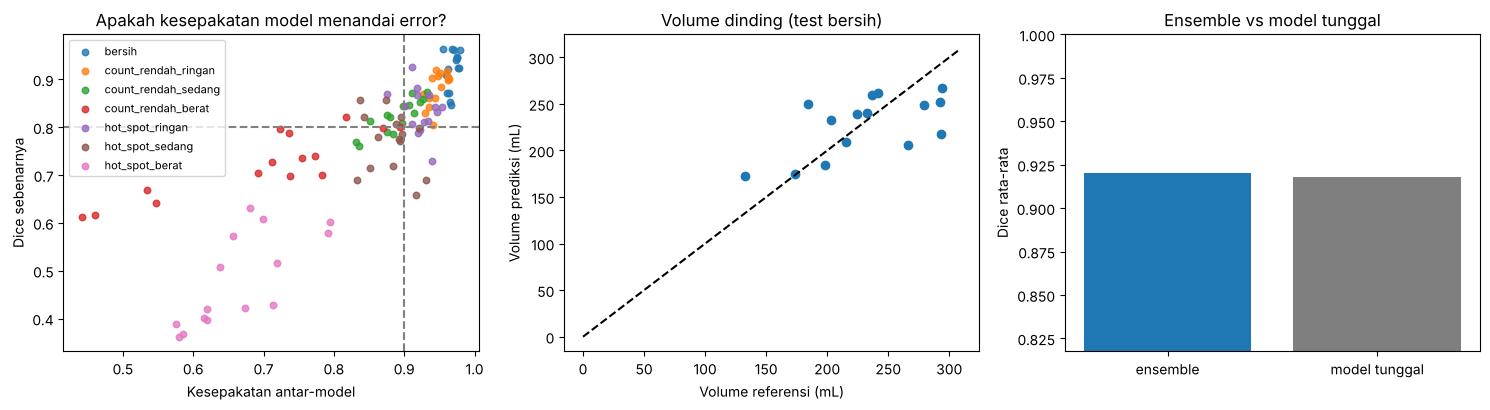

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
warna = plt.cm.tab10(np.arange(len(gangguan)))
for (n, _), cw in zip(gangguan, warna):
    g = st[st.gangguan == n]; ax[0].scatter(g.agreement, g.dice, label=n, color=cw, alpha=.8, s=22)
ax[0].axhline(POOR_DICE, ls="--", c="gray"); ax[0].axvline(AGREEMENT_MIN, ls="--", c="gray")
ax[0].set_xlabel("Kesepakatan antar-model"); ax[0].set_ylabel("Dice sebenarnya"); ax[0].set_title("Apakah kesepakatan model menandai error?"); ax[0].legend(fontsize=8)
ax[1].scatter(hasil.vol_ref_ml, hasil.volume_dinding_ml); lim = [0, max(hasil.vol_ref_ml.max(), hasil.volume_dinding_ml.max()) * 1.05]
ax[1].plot(lim, lim, "k--"); ax[1].set_xlabel("Volume referensi (mL)"); ax[1].set_ylabel("Volume prediksi (mL)"); ax[1].set_title("Volume dinding (test bersih)")
ax[2].bar(["ensemble", "model tunggal"], [hasil.dice_ensemble.mean(), hasil.dice_tunggal_rata2.mean()], color=["tab:blue", "tab:gray"])
ax[2].set_ylim(max(0, min(hasil.dice_ensemble.mean(), hasil.dice_tunggal_rata2.mean()) - .1), 1); ax[2].set_ylabel("Dice rata-rata"); ax[2].set_title("Ensemble vs model tunggal")
plt.tight_layout(); plt.savefig(WORK / "hasil" / "plot_hasil.png", dpi=150); plt.show()

## 9. Cek visual: referensi, prediksi, dan peta ketidakpastian

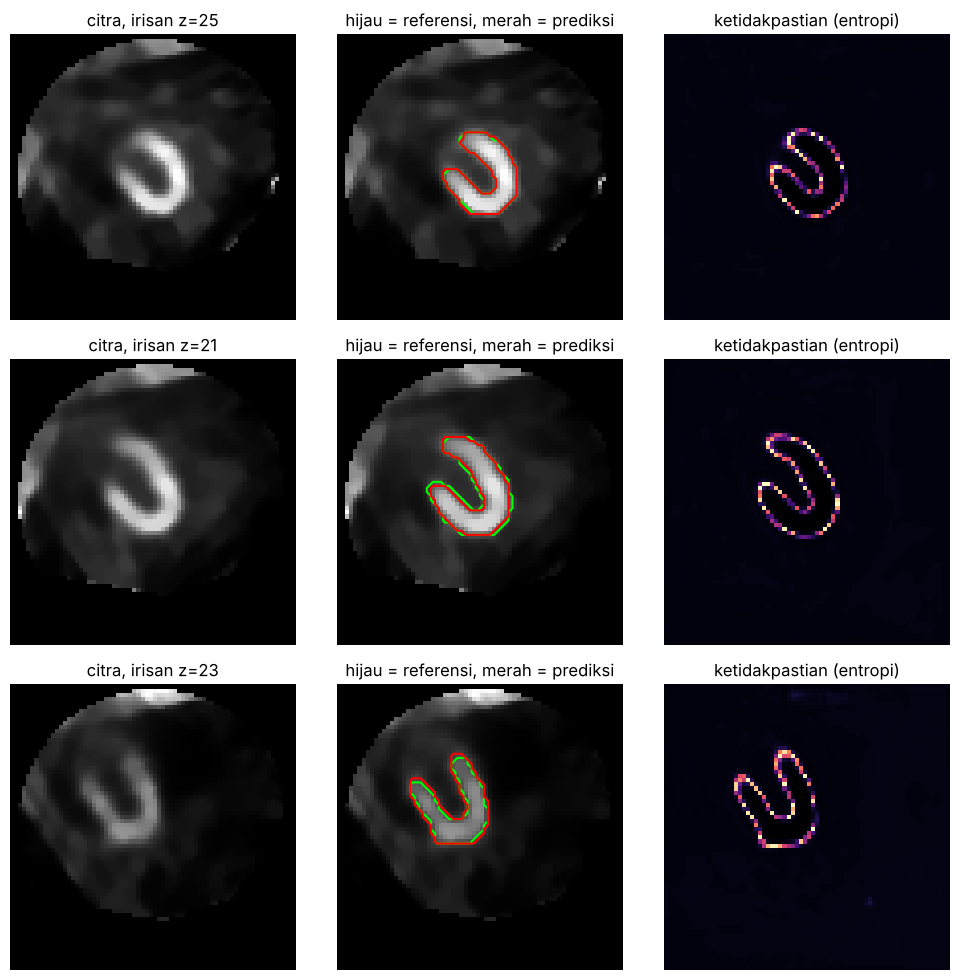

In [12]:
ids = list(simpan)[:3]
fig, ax = plt.subplots(len(ids), 3, figsize=(10, 3.3 * len(ids)))
for r, i in enumerate(ids):
    c = kasus[idx[i]]; final, ent = simpan[i]; z = int(np.round(ndi.center_of_mass(c["mask"])[2]))
    for a in ax[r]: a.axis("off")
    ax[r, 0].imshow(c["img"][:, :, z].T, cmap="gray", origin="lower"); ax[r, 0].set_title(f"citra, irisan z={z}")
    ax[r, 1].imshow(c["img"][:, :, z].T, cmap="gray", origin="lower")
    ax[r, 1].contour(c["mask"][:, :, z].T, levels=[.5], colors="lime"); ax[r, 1].contour(final[:, :, z].T, levels=[.5], colors="red")
    ax[r, 1].set_title("hijau = referensi, merah = prediksi"); ax[r, 2].imshow(ent[:, :, z].T, cmap="magma", origin="lower"); ax[r, 2].set_title("ketidakpastian (entropi)")
plt.tight_layout(); plt.savefig(WORK / "hasil" / "visual.png", dpi=130); plt.show()

## 10. Pakai ke satu DICOM baru

Fungsi di bawah menerima file DICOM mana pun dengan protokol yang sama, lalu mengeluarkan fitur dan flag QA. Keluarannya adalah alat bantu pendukung keputusan, bukan diagnosis.

In [13]:
def analisis_dicom(path):
    img, _ = baca_citra(path); final, _, _, f = analisis(img); return f
contoh = df[df.split == "test"].id.iloc[0]
pd.Series(analisis_dicom(dcm[contoh]))

volume_dinding_ml            209.472
n_komponen_mentah                  1
agreement                   0.971016
cv_keseragaman              0.272704
frak_hipoperfusi_relatif    0.342194
entropi_dinding             0.086517
rasio_hotspot               1.822978
flag_qa                             
perlu_dicek                        0
dtype: object

## 11. Keterbatasan yang harus ditulis di laporan

- Datanya satu pusat dan satu skanner (CZT pinhole), protokol rest-only, sekitar 80 pasien. Tidak ada validasi eksternal, jadi klaim generalisasi tidak boleh dibuat.
- Tidak ada label diagnosis. Fitur kuantitatif (keseragaman, fraksi hipoperfusi relatif) tidak divalidasi terhadap penyakit.
- Intensitas dinormalisasi per studi, jadi hanya fitur relatif yang bermakna.
- Masker referensi berasal dari satu proses anotasi, sehingga Dice terhadapnya juga mewarisi ketidakpastian anotasi itu.
- Uji QA memakai gangguan simulasi, bukan kegagalan klinis nyata.